# Case study: Supermicro (SMCI) and its 2015-2016 restatement

On 14 November 2018 Super Micro Computer's board concluded that its financial statements for
fiscal 2015 and 2016 should no longer be relied upon; the corrected numbers arrived in the
fiscal 2017 10-K, filed in May 2019. This notebook asks what the accounting-quality signals
built in this project would have said beforehand, using only data that was public at the time.

Everything runs from the local cache (`data/raw`, `data/processed`); the only network requests
happen if a cached EDGAR document is missing. Every number in the verdict (section 8) is a
variable computed in a cell above it, and every filing used is linked in section 9.

In [1]:
import re
import html as html_lib

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, Markdown, display
from plotly.subplots import make_subplots

from quality_screener import (
    case_study as cs, config, portfolios, prices, restatements as rs, scores, universe, viz,
)
from quality_screener.edgar import EdgarClient, archive_url

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")

TICKER = "SMCI"
client = EdgarClient()
firms = pd.read_parquet(universe.UNIVERSE_PATH)
firm = firms.set_index("ticker").loc[TICKER]
CIK = firm["cik"]
versions = pd.read_parquet(config.PROCESSED_DIR / "panel_all_versions.parquet")
scored = pd.read_parquet(scores.SCORES_PATH)
holdings = pd.read_parquet(portfolios.HOLDINGS_PATH)
daily = prices.load_daily([TICKER, prices.BENCHMARK])
calendar = prices.load_calendar()
filings = client.get_submissions(CIK).filings
SOURCES: dict[str, str] = {}  # accession number -> what it is; every filing used below


def cite(accn: str, label: str) -> str:
    """Record a filing as a source and return its EDGAR Archives URL."""
    SOURCES[accn] = label
    return archive_url(CIK, accn)


def pct(x: float, digits: int = 1) -> str:
    return f"{x * 100:+.{digits}f}%"


def text_of(accn: str, document: str) -> str:
    """Plain text of a filing document (cached EDGAR Archives copy)."""
    raw = client.get_filing_document(CIK, accn, document)
    return re.sub(r"\s+", " ", html_lib.unescape(re.sub(r"<[^>]+>", " ", raw)))


def show(fig: go.Figure, name: str) -> None:
    """Save as reports/figures/<name>.html and .png (house rule) and display the PNG."""
    viz.save_figures({name: fig})
    print(f"interactive version: reports/figures/{name}.html")
    display(Image(filename=str(viz.FIGURES_DIR / f"{name}.png"), width=1100))


print(firm[["name", "sic", "sic_description", "fiscal_year_end", "excluded_from_main"]].to_dict())

{'name': 'Supermicro', 'sic': 3571, 'sic_description': 'Electronic Computers', 'fiscal_year_end': '0630', 'excluded_from_main': False}


## 1. How SMCI was chosen

Candidates come from the data, not from memory (`quality_screener.restatements`): values that a
later filing reports more than 2% away from the as-first-reported value (revenue, net income,
CFO, receivables, total assets), screened for benign causes (discontinued operations, XBRL tag
changes or scale slips, acquisitions between the two filings, the 2018-2020 accounting-standard
adoption window) unless an 8-K item 4.02 non-reliance notice or a genuine 10-K/A backs them.
Events are ranked by the revision as a share of first-reported total assets.

In [2]:
revisions = rs.revisions(versions)
evidence = pd.concat(
    [rs.filing_evidence(client.get_submissions(c).filings).assign(cik=c) for c in firms["cik"]],
    ignore_index=True,
)
disc_ops = pd.concat(
    [rs.discontinued_ops_periods(client.get_company_facts(c)).assign(cik=c)
     for c in revisions["cik"].unique()],
    ignore_index=True,
)
classified = rs.add_size(
    rs.classify(revisions, evidence, disc_ops, rs.xbrl_only_amendments(versions)), versions
)
backed = rs.events(classified[classified["kept"] & classified["evidence"]])
backed = backed.merge(firms[["cik", "ticker", "name"]], on="cik")
n_revisions, n_backed = len(revisions), len(backed)
smci_rank = int(backed.index[backed["ticker"] == TICKER][0]) + 1
backed.head(15)[["ticker", "name", "field", "period_end", "original", "restated", "pct_change",
                 "size", "original_filed", "restated_filed", "restated_form", "nonreliance_8k"]]

,ticker,name,field,period_end,original,restated,pct_change,size,original_filed,restated_filed,restated_form,nonreliance_8k
0,AAPL,Apple Inc.,revenue,2008-09-27,3.248e+10,3.749e+10,0.1543,0.1267,2009-10-27,2010-01-25,10-K/A,NaT
1,SMCI,Supermicro,receivables,2016-06-30,2.889e+08,1.749e+08,-0.3946,0.09781,2016-08-26,2019-05-17,10-K,2018-11-15
2,BE,Bloom Energy,total_assets,2018-12-31,1.39e+09,1.522e+09,0.09508,0.09508,2019-03-22,2020-03-31,10-K,2020-02-12
3,SWK,Stanley Black & Decker,revenue,2019-12-28,1.444e+10,1.291e+10,-0.1059,0.07425,2020-02-21,2022-02-22,10-K,2022-01-26
4,PODD,Insulet Corporation,total_assets,2011-12-31,2.096e+08,2.213e+08,0.05601,0.05601,2012-02-28,2013-02-28,10-K/A,2013-02-08
5,MPWR,Monolithic Power Systems,net_income,2024-12-31,1.787e+09,1.592e+09,-0.1089,0.05381,2025-03-03,2026-02-27,10-K,2026-02-27
6,JKHY,Jack Henry & Associates,total_assets,2014-06-30,1.624e+09,1.681e+09,0.03473,0.03473,2014-08-27,2015-06-25,10-K/A,2015-05-07
7,VRT,Vertiv,net_income,2020-12-31,-1.836e+08,-3.273e+08,-0.7827,0.02832,2021-03-01,2021-04-30,10-K/A,2021-04-23
8,ITW,Illinois Tool Works,revenue,2010-12-31,1.587e+10,1.542e+10,-0.02865,0.02798,2011-02-28,2012-02-17,10-K,2011-08-30
9,KHC,Kraft Heinz,cfo,2016-12-31,5.238e+09,2.649e+09,-0.4943,0.02149,2017-02-23,2018-02-16,10-K,2017-11-06


In [3]:
print(f"{n_revisions} revisions above 2%; {n_backed} events backed by a 4.02 notice or a "
      f"10-K/A; {TICKER} ranks #{smci_rank}.")

1877 revisions above 2%; 20 events backed by a 4.02 notice or a 10-K/A; SMCI ranks #2.


## 2. Timeline: filings and the share price

Day 0 of an event is the first trading day the market could react: the filing day if EDGAR
accepted it before the 16:00 New York close, otherwise the next trading day. The abnormal return
is market-adjusted: the buy-and-hold return of SMCI minus that of SPY over days 0 to +4.

In [4]:
KINDS = {"10-K": "annual report", "10-K/A": "annual report amendment",
         "NT 10-K": "notification of late annual report", "8-K 4.02": "non-reliance notice (item 4.02)",
         "8-K 3.01": "listing standards notice (item 3.01)"}
items = filings["items"].fillna("").astype(str)
kind = np.select(
    [filings["form"].isin(["10-K", "10-K/A", "NT 10-K"]),
     (filings["form"] == "8-K") & items.str.contains("4.02", regex=False),
     (filings["form"] == "8-K") & items.str.contains("3.01", regex=False)],
    [filings["form"], "8-K 4.02", "8-K 3.01"], "",
)
timeline = filings.assign(kind=kind)
timeline = timeline[(timeline["kind"] != "") & timeline["filingDate"].between("2015-06-01", "2020-01-31")]
timeline = timeline.sort_values("filingDate", ignore_index=True)
timeline["day0"] = [cs.event_day(a, calendar) for a in timeline["acceptanceDateTime"]]
timeline["bhar_0_4"] = [cs.bhar(cs.event_window(daily, TICKER, d, before=0, after=4), 0, 4)
                        for d in timeline["day0"]]
timeline["what"] = timeline["kind"].map(KINDS)
timeline["link"] = [cite(a, f"{k} filed {d:%Y-%m-%d}") for a, k, d in
                    zip(timeline["accessionNumber"], timeline["kind"], timeline["filingDate"])]
timeline[["filingDate", "kind", "what", "reportDate", "day0", "bhar_0_4", "link"]]

,filingDate,kind,what,reportDate,day0,bhar_0_4,link
0,2015-08-31,NT 10-K,notification of late annual report,2015-06-30,2015-09-01,-0.08142,https://www.sec.gov/Archives/edgar/data/137536...
1,2015-09-10,10-K,annual report,2015-06-30,2015-09-10,0.1239,https://www.sec.gov/Archives/edgar/data/137536...
2,2015-11-16,10-K/A,annual report amendment,2015-06-30,2015-11-17,-0.06245,https://www.sec.gov/Archives/edgar/data/137536...
3,2016-08-26,10-K,annual report,2016-06-30,2016-08-29,0.03153,https://www.sec.gov/Archives/edgar/data/137536...
4,2017-08-29,NT 10-K,notification of late annual report,2017-08-29,2017-08-30,-0.03043,https://www.sec.gov/Archives/edgar/data/137536...
5,2017-09-15,8-K 3.01,listing standards notice (item 3.01),2017-09-14,2017-09-15,-0.1625,https://www.sec.gov/Archives/edgar/data/137536...
6,2017-11-20,8-K 3.01,listing standards notice (item 3.01),2017-11-16,2017-11-21,0.005726,https://www.sec.gov/Archives/edgar/data/137536...
7,2018-02-21,8-K 3.01,listing standards notice (item 3.01),2018-02-13,2018-02-21,-0.02443,https://www.sec.gov/Archives/edgar/data/137536...
8,2018-03-16,8-K 3.01,listing standards notice (item 3.01),2018-03-14,2018-03-19,-0.06547,https://www.sec.gov/Archives/edgar/data/137536...
9,2018-05-21,8-K 3.01,listing standards notice (item 3.01),2018-05-15,2018-05-22,0.0222,https://www.sec.gov/Archives/edgar/data/137536...


In [5]:
# Key dates, taken from the filing list above
notice = timeline[timeline["kind"] == "8-K 4.02"].iloc[0]
restated_10k = timeline[(timeline["kind"] == "10-K") & (timeline["reportDate"] == "2017-06-30")].iloc[0]
last_10k = timeline.loc[(timeline["kind"] == "10-K") & (timeline["filingDate"] < notice["filingDate"]), "filingDate"].max()
# the first late-filing notice after the last 10-K filed before the announcement (the missing FY2017 report)
late_notice = timeline[(timeline["kind"] == "NT 10-K") & (timeline["filingDate"] > last_10k)].iloc[0]
amendment_2015 = timeline[timeline["kind"] == "10-K/A"].iloc[0]
listing_notices = timeline[(timeline["kind"] == "8-K 3.01")
                           & timeline["filingDate"].between(late_notice["filingDate"], notice["filingDate"])]
RESTATED_ACCN = restated_10k["accessionNumber"]
NOTICE_DAY0 = notice["day0"]
notice_bhar = notice["bhar_0_4"]
years_10ka_to_notice = (notice["filingDate"] - amendment_2015["filingDate"]).days / 365.25
months_late_to_notice = (notice["filingDate"] - late_notice["filingDate"]).days / 30.44
n_listing_notices = len(listing_notices)

# Price drift from the late-filing notice (its day 0) to the day before the announcement
n_delay_days = int(((calendar >= late_notice["day0"]) & (calendar < NOTICE_DAY0)).sum())
drift = cs.event_window(daily, TICKER, NOTICE_DAY0, before=n_delay_days, after=0)
delay = drift[drift["rel_day"] < 0]
smci_delay_ret = (1 + delay["ret"]).prod() - 1
spy_delay_ret = (1 + delay["bench_ret"]).prod() - 1
bhar_late_to_notice = smci_delay_ret - spy_delay_ret
print(f"Non-reliance notice filed {notice['filingDate']:%Y-%m-%d}, accepted {notice['acceptanceDateTime']} -> day 0 {NOTICE_DAY0:%Y-%m-%d}")
print(f"5-day BHAR vs SPY from day 0: {pct(notice_bhar)}")
print(f"Late-filing notice for the FY2017 10-K: {late_notice['filingDate']:%Y-%m-%d}; "
      f"{len(listing_notices)} listing-standards notices between it and the announcement")
print(f"From that notice to the day before the announcement ({n_delay_days} trading days): "
      f"SMCI {pct(smci_delay_ret)}, SPY {pct(spy_delay_ret)}, BHAR {pct(bhar_late_to_notice)}")
print(f"Restated FY2017 10-K filed {restated_10k['filingDate']:%Y-%m-%d} ({RESTATED_ACCN})")

Non-reliance notice filed 2018-11-15, accepted 2018-11-15T21:53:25.000Z -> day 0 2018-11-16
5-day BHAR vs SPY from day 0: +16.1%
Late-filing notice for the FY2017 10-K: 2017-08-29; 8 listing-standards notices between it and the announcement
From that notice to the day before the announcement (307 trading days): SMCI -54.3%, SPY +14.1%, BHAR -68.4%
Restated FY2017 10-K filed 2019-05-17 (0001375365-19-000039)


In [6]:
# What the 8-K item 4.02 says: which periods, which kinds of error (keywords only, no long quotes)
notice_doc = filings.loc[filings["accessionNumber"] == notice["accessionNumber"], "primaryDocument"].item()
notice_text = text_of(notice["accessionNumber"], notice_doc)
nonreliance = notice_text[notice_text.find("4.02"):]
years_not_relied = sorted(set(re.findall(r"fiscal years ended June 30, (\d{4}) and (\d{4})", nonreliance)[0]))
error_topics = {topic: topic in nonreliance for topic in
                ["timing of recognition of revenue", "cut-off", "service elements", "inventory",
                 "balance sheet classification"]}
named = [t for t, found in error_topics.items() if found]
print("Annual statements not to be relied upon: FY" + ", FY".join(years_not_relied))
print("Error topics named:", error_topics)

# The 2015 10-K/A: did it change any reported value, and what did it amend?
k15 = timeline[(timeline["kind"] == "10-K") & (timeline["reportDate"] == "2015-06-30")].iloc[0]
v_orig = versions[versions["accn"] == k15["accessionNumber"]].set_index(["field", "period_end"])["val"]
v_amend = versions[versions["accn"] == amendment_2015["accessionNumber"]].set_index(["field", "period_end"])["val"]
both = pd.concat({"10-K": v_orig, "10-K/A": v_amend}, axis=1).dropna()
n_values_changed_2015 = int((both["10-K"] != both["10-K/A"]).sum())
amend_doc = filings.loc[filings["accessionNumber"] == amendment_2015["accessionNumber"], "primaryDocument"].item()
amend_text = text_of(amendment_2015["accessionNumber"], amend_doc)
note = amend_text[amend_text.lower().find("explanatory note"):][:2000]
amends_item_9a = "Item 9A" in note and "internal control over financial reporting" in note
print(f"2015 10-K/A: {n_values_changed_2015} of {len(both)} XBRL values changed; "
      f"amends Item 9A (internal control over financial reporting): {amends_item_9a}")

Annual statements not to be relied upon: FY2015, FY2016
Error topics named: {'timing of recognition of revenue': True, 'cut-off': True, 'service elements': True, 'inventory': True, 'balance sheet classification': True}
2015 10-K/A: 0 of 77 XBRL values changed; amends Item 9A (internal control over financial reporting): True


interactive version: reports/figures/case_study_smci_timeline.html


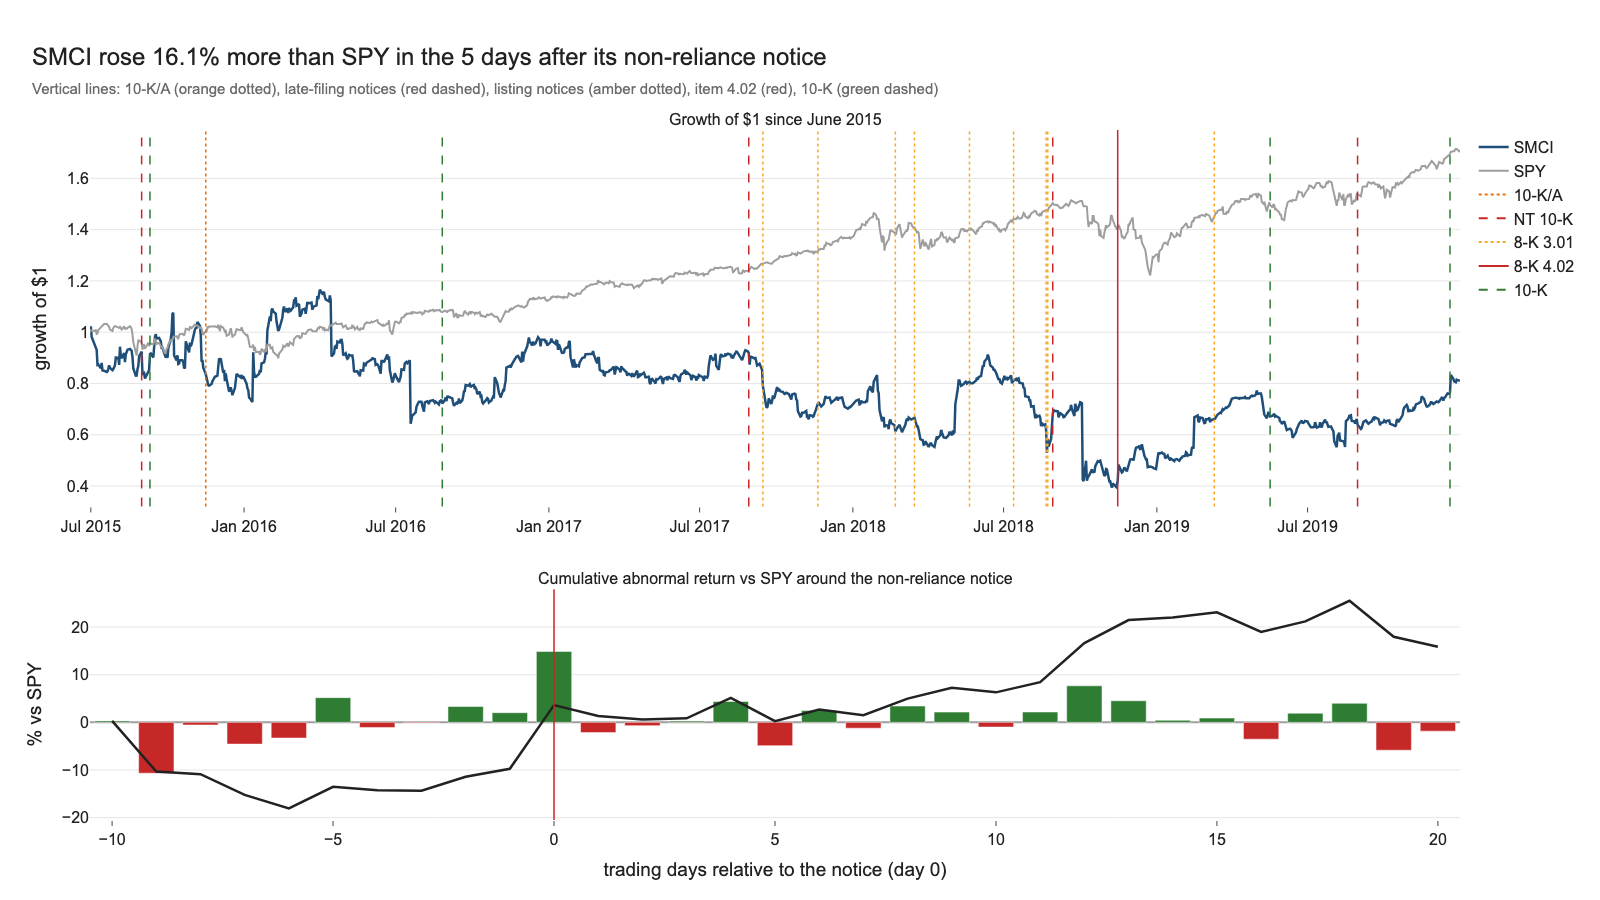

,date,rel_day,ret,bench_ret,abnormal,cum_bhar
0,2018-11-02,-10,-0.002901,-0.005923,0.003022,0.003022
1,2018-11-05,-9,-0.1011,0.005517,-0.1066,-0.1033
2,2018-11-06,-8,0.0008091,0.006328,-0.005519,-0.1089
3,2018-11-07,-7,-0.02425,0.02141,-0.04566,-0.1521
4,2018-11-08,-6,-0.0348,-0.001815,-0.03298,-0.1807
5,2018-11-09,-5,0.04206,-0.009768,0.05183,-0.1352
6,2018-11-12,-4,-0.02965,-0.01869,-0.01097,-0.1423
7,2018-11-13,-3,-0.003396,-0.001871,-0.001525,-0.1434
8,2018-11-14,-2,0.02641,-0.006837,0.03324,-0.1141
9,2018-11-15,-1,0.03071,0.01044,0.02027,-0.09756


In [7]:
start = pd.Timestamp("2015-06-30")
px = daily[daily["date"] >= start].pivot(index="date", columns="ticker", values="adj_close")
px = px.loc[: pd.Timestamp("2019-12-31")]
growth = px / px.iloc[0]
window = cs.event_window(daily, TICKER, NOTICE_DAY0, before=10, after=20)

fig = make_subplots(rows=2, cols=1, row_heights=[0.62, 0.38], vertical_spacing=0.12,
                    subplot_titles=["Growth of $1 since June 2015",
                                    "Cumulative abnormal return vs SPY around the non-reliance notice"])
fig.add_trace(go.Scatter(x=growth.index, y=growth[TICKER], name=TICKER, line=dict(color="#1f4e79", width=2.5)), 1, 1)
fig.add_trace(go.Scatter(x=growth.index, y=growth["SPY"], name="SPY", line=dict(color="#9e9e9e", width=2)), 1, 1)
marks = {"10-K/A": ("#ef6c00", "dot"), "NT 10-K": ("#c62828", "dash"), "8-K 3.01": ("#f9a825", "dot"),
         "8-K 4.02": ("#c62828", "solid"), "10-K": ("#2e7d32", "dash")}
for kind_, (color, dash) in marks.items():
    for d in timeline.loc[timeline["kind"] == kind_, "filingDate"]:
        fig.add_vline(x=d, line=dict(color=color, dash=dash, width=1.5), row=1, col=1)
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", name=kind_, line=dict(color=color, dash=dash)), 1, 1)
fig.add_trace(go.Bar(x=window["rel_day"], y=window["abnormal"] * 100, name="daily abnormal return (%)",
                     marker_color=np.where(window["abnormal"] >= 0, "#2e7d32", "#c62828"), showlegend=False), 2, 1)
fig.add_trace(go.Scatter(x=window["rel_day"], y=window["cum_bhar"] * 100, name="cumulative BHAR (%)",
                         line=dict(color=viz.TEXT, width=2.5), showlegend=False), 2, 1)
fig.add_vline(x=0, line=dict(color="#c62828", width=1.5), row=2, col=1)
fig.update_yaxes(title_text="growth of &#36;1", row=1, col=1)
fig.update_yaxes(title_text="% vs SPY", row=2, col=1)
fig.update_xaxes(title_text="trading days relative to the notice (day 0)", row=2, col=1)
fig.update_layout(height=viz.HEIGHT, legend=dict(x=1.01, y=1.0, xanchor="left"), margin=dict(r=140))
direction = "rose" if notice_bhar >= 0 else "fell"
viz.styled(fig, f"SMCI {direction} {abs(notice_bhar) * 100:.1f}% more than SPY in the 5 days after its non-reliance notice",
           "Vertical lines: 10-K/A (orange dotted), late-filing notices (red dashed), listing notices "
           "(amber dotted), item 4.02 (red), 10-K (green dashed)")
show(fig, "case_study_smci_timeline")
window

## 3. Original vs restated numbers

As first reported (FY2015 10-K, September 2015; FY2016 10-K, August 2016) against the values in
the restating filing (the FY2017 10-K, May 2019). That 10-K carries income statements for three
years but balance sheets for two, so FY2015 balance-sheet items have no restated value here.

In [8]:
affected = [pd.Timestamp(f"{y}-06-30") for y in years_not_relied]
comparison = cs.compare_versions(versions, CIK, RESTATED_ACCN, affected)
for accn in comparison["original_accn"].dropna().unique():
    cite(accn, "10-K as first reported")
cite(RESTATED_ACCN, "FY2017 10-K with restated FY2015-2016 comparatives")
shown = comparison.assign(
    original_m=comparison["original"] / 1e6, restated_m=comparison["restated"] / 1e6,
    pct_change=comparison["pct_change"].map(lambda x: pct(x) if pd.notna(x) else ""),
)
shown[["period_end", "field", "original_m", "restated_m", "pct_change", "original_accn"]].round(1)

/var/folders/wy/n8_b7b9x7xn54mw4wqp9z7080000gn/T/ipykernel_47482/1955734921.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  shown[["period_end", "field", "original_m", "restated_m", "pct_change", "original_accn"]].round(1)


,period_end,field,original_m,restated_m,pct_change,original_accn
0,2015-06-30,revenue,"1,991","1,954",-1.8%,0001628280-15-007025
1,2015-06-30,cogs,"1,671","1,648",-1.4%,0001628280-15-007025
2,2015-06-30,gross_profit,320.2,306.6,-4.3%,0001628280-15-007025
3,2015-06-30,sga,73.2,72.5,-0.9%,0001628280-15-007025
4,2015-06-30,net_income,101.9,92.6,-9.1%,0001628280-15-007025
5,2015-06-30,cfo,-44.6,-46.1,-3.3%,0001628280-15-007025
6,2015-06-30,receivables,322.6,NaN,,0001628280-15-007025
7,2015-06-30,current_assets,914.4,NaN,,0001628280-15-007025
8,2015-06-30,total_assets,"1,090",NaN,,0001628280-15-007025
9,2015-06-30,current_liabilities,454.1,NaN,,0001628280-15-007025


In [9]:
by_item = cs.compare_versions(versions, CIK, RESTATED_ACCN, affected).set_index(["period_end", "field"])
fy15, fy16 = affected
rev15_chg = by_item.loc[(fy15, "revenue"), "pct_change"]
ni15_chg = by_item.loc[(fy15, "net_income"), "pct_change"]
rev16_chg = by_item.loc[(fy16, "revenue"), "pct_change"]
ni16_chg = by_item.loc[(fy16, "net_income"), "pct_change"]
rec16_chg = by_item.loc[(fy16, "receivables"), "pct_change"]
cl16_chg = by_item.loc[(fy16, "current_liabilities"), "pct_change"]
largest = by_item["pct_change"].abs().idxmax()
print(f"Largest revision: {largest[1]} FY{largest[0].year} {pct(by_item.loc[largest, 'pct_change'])}")

Largest revision: receivables FY2016 -39.5%


## 4. Scores computed twice

(a) **As first reported**, what an analyst could compute at the time, built exactly like the
backtest's point-in-time panel (current-year values as first reported, prior-year values from
the same filing's comparatives); (b) **restated**, the same panel with every value the FY2017
10-K reports replaced by its restated figure. Both use the same market capitalisation (price
after the original filing), so differences come from the accounts only. On a single firm the
Beneish indices are not winsorised; the backtest's cross-sectionally winsorised M is shown
alongside.

In [10]:
pit = pd.read_parquet(config.PROCESSED_DIR / "panel_pit.parquet")
market_cap = prices.add_market_cap(pit[pit["cik"] == CIK], firms, daily, calendar).set_index("period_end")["market_cap"]
as_reported = cs.scores_for(cs.first_reported_long(versions, CIK), market_cap, versions=versions)
restated = cs.scores_for(cs.restated_long(versions, CIK, RESTATED_ACCN), market_cap, versions=versions)
# the panel's earlier rule, kept for comparison: prior-year values from the prior year's own 10-K
old_rule = cs.scores_for(cs.first_reported_long(versions, CIK), market_cap)
COLS = ["f_score", "z_score", "m_score", "accruals_cf", "m_dsri", "m_gmi", "m_aqi", "m_sgi",
        "m_depi", "m_sgai", "m_tata", "m_lvgi"]
YEARS = [2014, 2015, 2016, 2017]
twice = pd.concat({
    "as first reported": as_reported.set_index("fiscal_year").loc[YEARS, COLS],
    "restated": restated.set_index("fiscal_year").loc[YEARS, COLS],
}, names=["view", "fiscal_year"])
backtest_m = scored[scored["cik"] == CIK].set_index("fiscal_year").loc[YEARS, "m_score"]
twice["m_flag (> -1.78)"] = twice["m_score"] > scores.M_THRESHOLD
twice

f_score  z_score  m_score  accruals_cf  m_dsri  m_gmi  m_aqi  m_sgi  m_depi  m_sgai   m_tata  m_lvgi  m_flag (> -1.78)
view              fiscal_year                                                                                                                        
as first reported 2014               6    5.418   -1.925      0.06667   1.129 0.8956 0.7035  1.262   1.625  0.8383   0.0598   1.006             False
                  2015               5    4.903    -1.54       0.1553   1.117 0.9558 0.7747  1.357   0.978  0.8841   0.1344   1.057              True
                  2016               4    4.758   -1.871     -0.03147   0.805  1.075      3  1.113  0.7199   1.236 -0.03045  0.8293             False
                  2017               3    3.567    -1.34       0.1205   1.658  1.055 0.9331  1.117  0.8552   1.007   0.1076   1.176              True
restated          2014               6    5.418   -1.925      0.06667   1.129 0.8956 0.7035  1.262   1.625  0.8383   0.0598   1.006             False
                  2015               5    4.826   -1.565       0.1471   1.138 0.9799 0.7747  1.332  0.9825  0.8923   0.1273   1.057              True
                  2016               4    4.488   -1.917     -0.03148  0.4763  1.056  3.643  1.138  0.7166   1.196 -0.03014  0.9038             False
                  2017               3    3.567    -1.34       0.1205   1.658  1.055 0.9331  1.117  0.8552   1.007   0.1076   1.176              True

In [11]:
print("Backtest's winsorised M (as first reported):", backtest_m.round(3).to_dict())
m_raw_15 = twice.loc[("as first reported", 2015), "m_score"]
m_raw_16 = twice.loc[("as first reported", 2016), "m_score"]
m_bt_15, m_bt_16 = backtest_m[2015], backtest_m[2016]
m_rest_15 = twice.loc[("restated", 2015), "m_score"]
m_rest_16 = twice.loc[("restated", 2016), "m_score"]
m_first_17 = twice.loc[("as first reported", 2017), "m_score"]
old_17 = old_rule.set_index("fiscal_year").loc[2017]
m_old_17, dsri_old_17 = old_17["m_score"], old_17["m_dsri"]
dsri_first_17 = twice.loc[("as first reported", 2017), "m_dsri"]
fy17_filed = as_reported.set_index("fiscal_year").loc[2017, "availability_date"]
aqi_16 = (twice.loc[("as first reported", 2016), "m_aqi"], twice.loc[("restated", 2016), "m_aqi"])
dsri_16 = (twice.loc[("as first reported", 2016), "m_dsri"], twice.loc[("restated", 2016), "m_dsri"])
z_16 = (twice.loc[("as first reported", 2016), "z_score"], twice.loc[("restated", 2016), "z_score"])
f_15, f_16 = twice.loc[("as first reported", 2015), "f_score"], twice.loc[("as first reported", 2016), "f_score"]
acc_15 = twice.loc[("as first reported", 2015), "accruals_cf"]
acc_pct_15 = (scored.loc[scored["fiscal_year"] == 2015, "accruals_cf"] < acc_15).mean()
print(f"FY2015 accruals {acc_15:.3f}: higher than {acc_pct_15:.0%} of FY2015 firm-years in the universe")
print(f"FY2017 (first reported {fy17_filed:%Y-%m-%d}), prior year from the same filing: "
      f"DSRI {dsri_first_17:.2f}, M {m_first_17:.2f}")
print(f"FY2017 under the panel's earlier rule (prior year from the original FY2016 10-K): "
      f"DSRI {dsri_old_17:.2f}, M {m_old_17:.2f}")

Backtest's winsorised M (as first reported): {2014: -1.93, 2015: -1.848, 2016: -1.871, 2017: -1.34}
FY2015 accruals 0.155: higher than 98% of FY2015 firm-years in the universe
FY2017 (first reported 2019-05-17), prior year from the same filing: DSRI 1.66, M -1.34
FY2017 under the panel's earlier rule (prior year from the original FY2016 10-K): DSRI 1.00, M -1.89


Note on FY2017: its numbers were first reported in the restating filing itself. The panel used
to take FY2016 (the base year of every change ratio) from the original 2016 10-K, so FY2017's
ratios divided a restated year by an unrestated one. This case study is why the panel now takes
prior-year values from the comparatives in the same filing (CLAUDE.md rule 2); both versions of
FY2017 are printed above.

## 5. Red-flag radar for FY2016, as first reported

FY2016 is the last annual report SMCI filed before the non-reliance notice. Each axis is SMCI's
percentile among S&P 500 non-financials that year (1 = most suspicious); dashed = median firm,
dotted = FY2015.

interactive version: reports/figures/case_study_smci_radar_FY2016.html


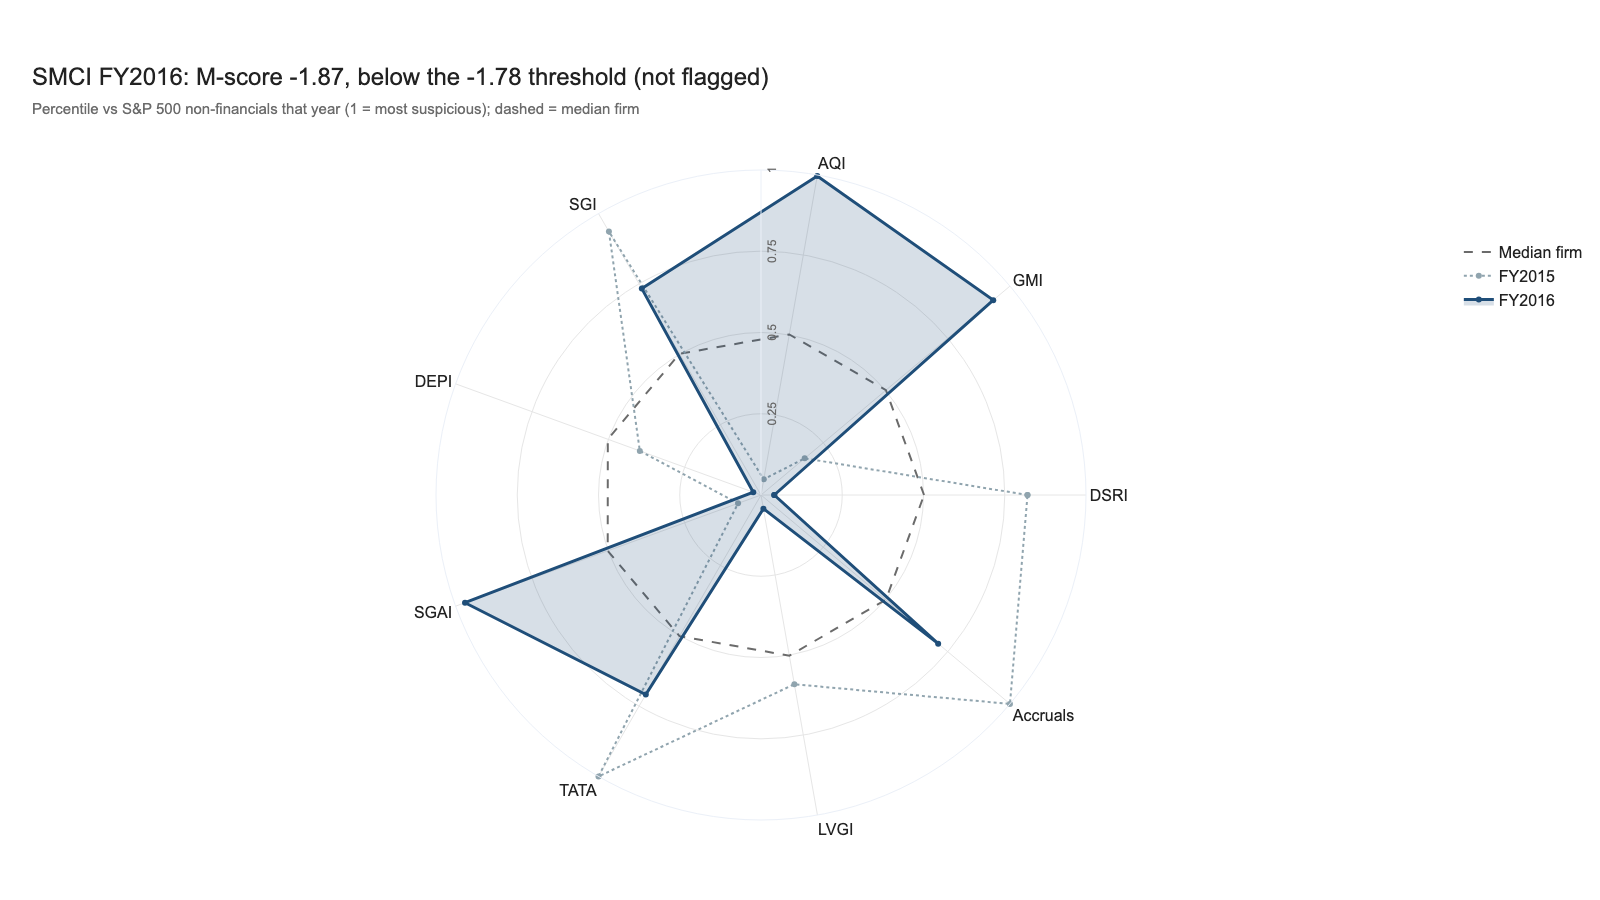

,percentile FY2016
DSRI,0.04
GMI,0.93
AQI,1
SGI,0.73
DEPI,0.03
SGAI,0.97
TATA,0.71
LVGI,0.04
Accruals,0.71


In [12]:
radar_year = 2016
radar = viz.red_flag_radar(TICKER, radar_year, scored)
show(radar, f"case_study_smci_radar_FY{radar_year}")
radar_pct = viz.red_flag_percentiles(scored, radar_year).loc[TICKER]
top_axes = radar_pct.sort_values(ascending=False).head(3)
top_axis, top_axis_pct = top_axes.index[0], top_axes.iloc[0]
radar_pct.round(2).to_frame("percentile FY2016")

## 6. Where SMCI sat in the quintile sorts before the announcement

Monthly holdings from `build_portfolios.py` (main sample, Q5 = high quality; for the F groups,
3 = high). The window of interest is 12-24 months before the non-reliance notice.

In [13]:
held = holdings[holdings["ticker"] == TICKER]
grid = held.pivot(index="t", columns="signal", values="bucket").loc["2016-01-01":"2020-03-31"]
grid = grid.reindex(columns=[s for s in portfolios.SIGNAL_ORDER if s in grid.columns])
grid

signal,f_group,f_score,altman_z,beneish_m,accruals_cf,composite,accruals_bs
t,,,,,,,
2016-01-29,2,2,4,1,1,1,1
2016-02-29,2,2,4,1,1,1,1
2016-03-31,2,2,4,1,1,1,1
2016-04-29,2,2,4,1,1,1,1
2016-05-31,2,2,4,1,1,1,1
2016-06-30,2,2,4,1,1,1,1
2016-07-29,2,2,4,1,1,1,1
2016-08-31,2,1,4,1,2,1,2
2016-09-30,2,1,4,1,2,1,2


In [14]:
formation = portfolios.formation_dates(calendar, config.START_YEAR + 2, pd.Timestamp.today())
w_start, w_end = notice["filingDate"] - pd.DateOffset(months=24), notice["filingDate"] - pd.DateOffset(months=12)
in_window = formation[(formation > w_start) & (formation <= w_end)]
held_window = grid.reindex(in_window)
n_window = len(in_window)
n_held = int(held_window["composite"].notna().sum())
n_composite_q1 = int((held_window["composite"] == 1).sum())
n_m_q1 = int((held_window["beneish_m"] == 1).sum())
n_f_q1 = int((held_window["f_score"] == 1).sum())
z_buckets = sorted(held_window["altman_z"].dropna().astype(int).unique())
acc_buckets = sorted(held_window["accruals_cf"].dropna().astype(int).unique())
last_held = grid.index[grid["composite"].notna() & (grid.index < notice["filingDate"])].max()
first_back = grid.index[grid["composite"].notna() & (grid.index > notice["filingDate"])].min()
months_dropped = len(formation[(formation > last_held) & (formation < first_back)])
print(f"Window {w_start:%Y-%m-%d} to {w_end:%Y-%m-%d}: {n_window} formation dates, SMCI held in {n_held}")
print(f"Composite Q1 in {n_composite_q1}, Beneish M Q1 in {n_m_q1}, F-score quintile Q1 in {n_f_q1}")
print(f"Altman Z buckets {z_buckets}, accruals buckets {acc_buckets}")
print(f"Last held {last_held:%Y-%m-%d}; dropped as stale for {months_dropped} months; back {first_back:%Y-%m-%d}")

Window 2016-11-15 to 2017-11-15: 12 formation dates, SMCI held in 11
Composite Q1 in 11, Beneish M Q1 in 11, F-score quintile Q1 in 11
Altman Z buckets [np.int64(4)], accruals buckets [np.int64(2)]
Last held 2017-09-29; dropped as stale for 26 months; back 2019-12-31


## 7. Verdict

In [15]:
def yes_no(flag: bool) -> str:
    return "yes" if flag else "no"


if bhar_late_to_notice < 0 < notice_bhar:
    market_reading = ("The stock lagged during the delay and rose on the notice, consistent with "
                      "the announcement resolving uncertainty rather than delivering new bad news.")
elif notice_bhar < 0:
    market_reading = "The notice itself was received as bad news."
else:
    market_reading = "The stock outperformed both during the delay and on the notice."

verdict = f"""
**What flagged SMCI early**

- **The composite quality sort.** In the {n_window} monthly sorts 12-24 months before the notice
  (section 6), SMCI was held in {n_held} and sat in the lowest-quality composite quintile (Q1) in
  {n_composite_q1} of them. The composite was pulled down by Beneish M (Q1 in {n_m_q1} of
  {n_held}) and the Piotroski F quintiles (Q1 in {n_f_q1}).
- **Cash-flow accruals in FY2015.** As first reported, FY2015 accruals were {acc_15:.3f} of average
  assets, higher than {acc_pct_15:.0%} of that year's firm-years (section 4): earnings ran well ahead
  of operating cash flow, the pattern Sloan (1996) associates with low earnings quality.
- **Filings rather than numbers.** The FY2015 10-K/A ({amendment_2015['filingDate']:%Y-%m-%d}) changed
  {n_values_changed_2015} reported values but amended Item 9A on internal control over financial
  reporting: {yes_no(amends_item_9a)} (section 2), {years_10ka_to_notice:.1f} years before the
  non-reliance notice. The FY2017 10-K never arrived on time: a late-filing notice on
  {late_notice['filingDate']:%Y-%m-%d} and {len(listing_notices)} listing-standards notices before the
  announcement followed, and the 15-month staleness rule dropped SMCI from every sort after
  {last_held:%Y-%m-%d} for {months_dropped} months (section 6).

**What missed it**

- **Beneish M at its own threshold.** With the backtest's winsorised indices, M was
  {m_bt_15:.2f} (FY2015) and {m_bt_16:.2f} (FY2016), both below -1.78. On raw indices FY2015 was
  {m_raw_15:.2f} (flagged) and FY2016 {m_raw_16:.2f} (not), so the FY2015 call hinges on
  winsorisation. The relative ranking (Q1) was more informative than the absolute cut-off.
- **DSRI, the receivables index.** The restatement's largest change was FY2016 receivables
  ({pct(rec16_chg)}), but DSRI as first reported was {dsri_16[0]:.2f}, below 1: receivables were not
  growing faster than sales. Current liabilities moved the other way ({pct(cl16_chg)}); the notice
  mentions balance sheet classification errors: {yes_no(error_topics['balance sheet classification'])}.
  A classification correction like that changes no income-statement ratio.
- **Revenue and earnings scale.** The notice names {', '.join(named[:-1])} and {named[-1]} (section 2):
  mostly timing, so the annual totals moved little: revenue {pct(rev15_chg)} (FY2015) and
  {pct(rev16_chg)} (FY2016), net income {pct(ni15_chg)} and {pct(ni16_chg)}. Restated M is
  {m_rest_15:.2f} and {m_rest_16:.2f}, close to the original values.
- **Altman Z.** As first reported Z was {z_16[0]:.2f} in FY2016 ({z_16[1]:.2f} restated), deep in the
  safe zone: Z measures distress, and SMCI was not distressed.
- **Piotroski F groups.** F was {f_15:.0f} (FY2015) and {f_16:.0f} (FY2016): the middle group, not
  the 0-3 low group.

**Two further lessons**

- **AQI and the radar.** SMCI's most extreme FY2016 radar axis was {top_axis} (percentile
  {top_axis_pct:.2f}; the top three were {', '.join(top_axes.index)}, section 5). AQI was
  {aqi_16[0]:.2f} as first reported ({aqi_16[1]:.2f} restated): a jump in the share of assets other than
  current assets and PPE, the kind of signal Beneish's AQI is meant to catch, but on its own not
  enough to push M over -1.78.
- **Mixed vintages blunt change ratios, so the panel changed.** FY2017 was first reported
  ({fy17_filed:%Y-%m-%d}) in the restating filing. Under the panel's earlier rule its base year came
  from the original FY2016 10-K: DSRI {dsri_old_17:.2f}, M {m_old_17:.2f}. Taking FY2016 from the
  same filing's restated comparatives gives DSRI {dsri_first_17:.2f} and M {m_first_17:.2f} (above
  -1.78: {yes_no(m_first_17 > scores.M_THRESHOLD)}). The panel now uses same-filing comparatives
  for every firm. It does not change the forecast here: FY2017 arrived after the notice, and its
  period had ended more than 15 months before, so it never entered a sort.

**The market.** In the five days after the notice SMCI moved {pct(notice_bhar)} relative to SPY
(section 2). Over the {n_delay_days} trading days from the late-filing notice to the day before
the announcement it had returned {pct(smci_delay_ret)} against {pct(spy_delay_ret)} for SPY
(BHAR {pct(bhar_late_to_notice)}). {market_reading}
"""
display(Markdown(verdict))


**What flagged SMCI early**

- **The composite quality sort.** In the 12 monthly sorts 12-24 months before the notice
  (section 6), SMCI was held in 11 and sat in the lowest-quality composite quintile (Q1) in
  11 of them. The composite was pulled down by Beneish M (Q1 in 11 of
  11) and the Piotroski F quintiles (Q1 in 11).
- **Cash-flow accruals in FY2015.** As first reported, FY2015 accruals were 0.155 of average
  assets, higher than 98% of that year's firm-years (section 4): earnings ran well ahead
  of operating cash flow, the pattern Sloan (1996) associates with low earnings quality.
- **Filings rather than numbers.** The FY2015 10-K/A (2015-11-16) changed
  0 reported values but amended Item 9A on internal control over financial
  reporting: yes (section 2), 3.0 years before the
  non-reliance notice. The FY2017 10-K never arrived on time: a late-filing notice on
  2017-08-29 and 8 listing-standards notices before the
  announcement followed, and the 15-month staleness rule dropped SMCI from every sort after
  2017-09-29 for 26 months (section 6).

**What missed it**

- **Beneish M at its own threshold.** With the backtest's winsorised indices, M was
  -1.85 (FY2015) and -1.87 (FY2016), both below -1.78. On raw indices FY2015 was
  -1.54 (flagged) and FY2016 -1.87 (not), so the FY2015 call hinges on
  winsorisation. The relative ranking (Q1) was more informative than the absolute cut-off.
- **DSRI, the receivables index.** The restatement's largest change was FY2016 receivables
  (-39.5%), but DSRI as first reported was 0.80, below 1: receivables were not
  growing faster than sales. Current liabilities moved the other way (+12.7%); the notice
  mentions balance sheet classification errors: yes.
  A classification correction like that changes no income-statement ratio.
- **Revenue and earnings scale.** The notice names timing of recognition of revenue, cut-off, service elements, inventory and balance sheet classification (section 2):
  mostly timing, so the annual totals moved little: revenue -1.8% (FY2015) and
  +0.4% (FY2016), net income -9.1% and +0.1%. Restated M is
  -1.56 and -1.92, close to the original values.
- **Altman Z.** As first reported Z was 4.76 in FY2016 (4.49 restated), deep in the
  safe zone: Z measures distress, and SMCI was not distressed.
- **Piotroski F groups.** F was 5 (FY2015) and 4 (FY2016): the middle group, not
  the 0-3 low group.

**Two further lessons**

- **AQI and the radar.** SMCI's most extreme FY2016 radar axis was AQI (percentile
  1.00; the top three were AQI, SGAI, GMI, section 5). AQI was
  3.00 as first reported (3.64 restated): a jump in the share of assets other than
  current assets and PPE, the kind of signal Beneish's AQI is meant to catch, but on its own not
  enough to push M over -1.78.
- **Mixed vintages blunt change ratios, so the panel changed.** FY2017 was first reported
  (2019-05-17) in the restating filing. Under the panel's earlier rule its base year came
  from the original FY2016 10-K: DSRI 1.00, M -1.89. Taking FY2016 from the
  same filing's restated comparatives gives DSRI 1.66 and M -1.34 (above
  -1.78: yes). The panel now uses same-filing comparatives
  for every firm. It does not change the forecast here: FY2017 arrived after the notice, and its
  period had ended more than 15 months before, so it never entered a sort.

**The market.** In the five days after the notice SMCI moved +16.1% relative to SPY
(section 2). Over the 307 trading days from the late-filing notice to the day before
the announcement it had returned -54.3% against +14.1% for SPY
(BHAR -68.4%). The stock lagged during the delay and rose on the notice, consistent with the announcement resolving uncertainty rather than delivering new bad news.


## 8. Sources

In [16]:
cite(notice["accessionNumber"], "8-K items 2.02 and 4.02 (non-reliance)")
cite(amendment_2015["accessionNumber"], "FY2015 10-K/A (Item 8 and Item 9A)")
rows = [{"accession": a, "filing": label, "url": archive_url(CIK, a)} for a, label in sorted(SOURCES.items())]
rows += [
    {"accession": "-", "filing": "XBRL company facts (all reported values)",
     "url": f"https://data.sec.gov/api/xbrl/companyfacts/CIK{CIK}.json"},
    {"accession": "-", "filing": "Submissions (filing list, 8-K item numbers, acceptance times)",
     "url": f"https://data.sec.gov/submissions/CIK{CIK}.json"},
]
display(Markdown("\n".join(f"- [{r['filing']}]({r['url']}) `{r['accession']}`" for r in rows)))
print(f"{len(SOURCES)} filings cited; network requests to sec.gov in this run: {client.network_calls}")

- [8-K 3.01 filed 2019-03-11](https://www.sec.gov/Archives/edgar/data/1375365/000137536519000010/) `0001375365-19-000010`
- [FY2017 10-K with restated FY2015-2016 comparatives](https://www.sec.gov/Archives/edgar/data/1375365/000137536519000039/) `0001375365-19-000039`
- [NT 10-K filed 2019-08-30](https://www.sec.gov/Archives/edgar/data/1375365/000137536519000049/) `0001375365-19-000049`
- [10-K filed 2019-12-19](https://www.sec.gov/Archives/edgar/data/1375365/000137536519000079/) `0001375365-19-000079`
- [NT 10-K filed 2015-08-31](https://www.sec.gov/Archives/edgar/data/1375365/000162828015006916/) `0001628280-15-006916`
- [10-K as first reported](https://www.sec.gov/Archives/edgar/data/1375365/000162828015007025/) `0001628280-15-007025`
- [FY2015 10-K/A (Item 8 and Item 9A)](https://www.sec.gov/Archives/edgar/data/1375365/000162828015008827/) `0001628280-15-008827`
- [10-K as first reported](https://www.sec.gov/Archives/edgar/data/1375365/000162828016019274/) `0001628280-16-019274`
- [NT 10-K filed 2017-08-29](https://www.sec.gov/Archives/edgar/data/1375365/000162828017008984/) `0001628280-17-008984`
- [8-K 3.01 filed 2017-09-15](https://www.sec.gov/Archives/edgar/data/1375365/000162828017009319/) `0001628280-17-009319`
- [8-K 3.01 filed 2017-11-20](https://www.sec.gov/Archives/edgar/data/1375365/000162828017011731/) `0001628280-17-011731`
- [8-K 3.01 filed 2018-02-21](https://www.sec.gov/Archives/edgar/data/1375365/000162828018001928/) `0001628280-18-001928`
- [8-K 3.01 filed 2018-03-16](https://www.sec.gov/Archives/edgar/data/1375365/000162828018003318/) `0001628280-18-003318`
- [8-K 3.01 filed 2018-05-21](https://www.sec.gov/Archives/edgar/data/1375365/000162828018007027/) `0001628280-18-007027`
- [8-K 3.01 filed 2018-07-13](https://www.sec.gov/Archives/edgar/data/1375365/000162828018009214/) `0001628280-18-009214`
- [8-K 3.01 filed 2018-08-21](https://www.sec.gov/Archives/edgar/data/1375365/000162828018011280/) `0001628280-18-011280`
- [8-K 3.01 filed 2018-08-23](https://www.sec.gov/Archives/edgar/data/1375365/000162828018011320/) `0001628280-18-011320`
- [NT 10-K filed 2018-08-29](https://www.sec.gov/Archives/edgar/data/1375365/000162828018011521/) `0001628280-18-011521`
- [8-K items 2.02 and 4.02 (non-reliance)](https://www.sec.gov/Archives/edgar/data/1375365/000162828018014419/) `0001628280-18-014419`
- [XBRL company facts (all reported values)](https://data.sec.gov/api/xbrl/companyfacts/CIK0001375365.json) `-`
- [Submissions (filing list, 8-K item numbers, acceptance times)](https://data.sec.gov/submissions/CIK0001375365.json) `-`

19 filings cited; network requests to sec.gov in this run: 0
